# Geospatial Vector Data

## goals of the lecture
- the vector data and ESRI Shapefile
- the geodataframe in geopandas
- spatial projection

**based on the open data of:**

- [ISTAT](https://www.istat.it/it/archivio/222527) Italian National Institute of Statistic

### requirements

- python knowledge
- pandas

### status

*"The Earth isn't flat!!!"*


---

## import modules

### Block 01 · Learning goal and AI prompt

**Learning objective:** Separate environment setup from analysis.

**Check after execution:** Did installation finish successfully?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Install geopandas, matplotlib, requests, folium and mapclassify in this notebook using a notebook-aware pip command. Reuse existing variables and generate only this step. Do not invent results.


In [123]:
%pip install -q geopandas matplotlib requests folium mapclassify

## install geopandas



### Block 02 · Learning goal and AI prompt

**Learning objective:** Recognise the roles of geospatial, tabular and plotting libraries.

**Check after execution:** Which library adds spatial methods to a table?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Import GeoPandas as gpd, pandas as pd, matplotlib.pyplot as plt, and Path from pathlib. Reuse existing variables and generate only this step. Do not invent results.


In [124]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Block 03 · Learning goal and AI prompt

**Learning objective:** Identify dependencies for interactive maps.

**Check after execution:** Which imports support GeoDataFrame.explore?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Import GeoPandas as gpd, folium and mapclassify. Reuse existing variables and generate only this step. Do not invent results.


In [125]:
import geopandas as gpd
import folium
import mapclassify

# Let's start with GeoPandas

## Importing geospatial data

geopandas supports all the vector format offered by the [fiona project](https://github.com/Toblerity/Fiona) or [gdal/ogr](https://www.gdal.org/ogr_formats.html) (more formats and faster)


we will play with the geospatial data offered by [ISTAT](https://istat.it)

### administrative borders
[https://www.istat.it/it/archivio/222527](https://www.istat.it/it/archivio/222527)

Here the zip file with all the different administrative levels of Italy
<br/>
[https://www.istat.it/storage/cartografia/confini_amministrativi/generalizzati/2026/Limiti01012026_g.zip](https://www.istat.it/storage/cartografia/confini_amministrativi/generalizzati/2026/Limiti01012026_g.zip)

Download and investigate the data

### Block 04 · Learning goal and AI prompt

**Learning objective:** Trace administrative layers back to an original dated source.

**Check after execution:** Which directory corresponds to each administrative level?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Download the official ISTAT 2026 generalised ZIP into data_2026 using requests with HTTP error checking. Extract its administrative directories without changing the working directory. Define YEAR, ISTAT_URL, DATA, archive, source_dir and read_istat(prefix). The function must require exactly one matching Shapefile. List the Shapefiles relative to source_dir. Use https://www.istat.it/storage/cartografia/confini_amministrativi/generalizzati/2026/Limiti01012026_g.zip . Reuse existing variables and generate only this step. Do not invent results.


In [126]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path
from zipfile import ZipFile

YEAR = 2026
ISTAT_URL = ("https://www.istat.it/storage/cartografia/"
             "confini_amministrativi/generalizzati/2026/Limiti01012026_g.zip")
DATA = Path("data_2026").resolve()
DATA.mkdir(exist_ok=True)
archive = DATA / "Limiti01012026_g.zip"
if not archive.exists():
    response = requests.get(ISTAT_URL, timeout=120)
    response.raise_for_status()
    archive.write_bytes(response.content)
source_dir = DATA / "istat"
if not list(source_dir.rglob("*.shp")):
    with ZipFile(archive) as z:
        z.extractall(source_dir)

def read_istat(prefix):
    candidates = list(source_dir.rglob(prefix + "*.shp"))
    if len(candidates) != 1:
        raise ValueError(f"Expected one {prefix} layer, found {candidates}")
    return gpd.read_file(candidates[0])

print([str(p.relative_to(source_dir)) for p in source_dir.rglob("*.shp")])

['Reg01012026_g/Reg01012026_g_WGS84.shp', 'Com01012026_g/Com01012026_g_WGS84.shp', 'RipGeo01012026_g/RipGeo01012026_g_WGS84.shp', 'ProvCM01012026_g/ProvCM01012026_g_WGS84.shp']


Directory listening

### Block 05 · Learning goal and AI prompt

**Learning objective:** Read the archive structure before selecting a layer.

**Check after execution:** Does this archive contain one layer or several?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. List the immediate directories in source_dir. Reuse existing variables and generate only this step. Do not invent results.


In [127]:
list(source_dir.iterdir())

[PosixPath('/content/data_2026/istat/Reg01012026_g'),
 PosixPath('/content/data_2026/istat/Com01012026_g'),
 PosixPath('/content/data_2026/istat/RipGeo01012026_g'),
 PosixPath('/content/data_2026/istat/ProvCM01012026_g')]

- RipGeo01012026_g<br/>&nbsp;folder with the macro-regions of Italy
- Reg01012026_g<br/>&nbsp;folder with the regions of Italy
- ProvCM01012026_g<br/>&nbsp;folder with the provinces of Italy
- Com01012026_g<br/>&nbsp;folder with the municipalities of Italy

#### Inspect the the macro regions


### Block 06 · Learning goal and AI prompt

**Learning objective:** Choose the macroregion layer explicitly.

**Check after execution:** Does the filename identify the intended administrative level?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Find the unique RipGeo Shapefile below source_dir, store its Path as macroregions_path and display its parent directory. Reuse existing variables and generate only this step. Do not invent results.


In [128]:
macroregions_path = next(source_dir.rglob("RipGeo*.shp"))
macroregions_path.parent

PosixPath('/content/data_2026/istat/RipGeo01012026_g')

### Block 07 · Learning goal and AI prompt

**Learning objective:** Understand that a Shapefile is a set of related files.

**Check after execution:** Are geometry, attributes, index and CRS files all present?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. List the filenames beside macroregions_path. Reuse existing variables and generate only this step. Do not invent results.


In [129]:
[p.name for p in macroregions_path.parent.iterdir()]

['RipGeo01012026_g_WGS84.shp',
 'RipGeo01012026_g_WGS84.shx',
 'RipGeo01012026_g_WGS84.prj',
 'RipGeo01012026_g_WGS84.dbf']

### ESRI Shapefile

this is a *ESRI Shapefile* (an old but common used format for the geospatial vector data)

The format is proprietary and some format specifications are public.
A "ESRI Shapefile" is a collection of different files with the same name and different extensions.

The public specifications are for the extensions:

| extension | meaning       | content of the file                                                  |
| --------- | ------------- | -------------------------------------------------------------------- |
| .shp      | shape         | the geometries (point, line, polygon)                                |
| .dbf      | database file | the attributes to associate with the geometries                      |
| .shx      | shape indices | the indices to join the geometries with the attributes               |
| .prj      | projection    | the rule to understand the kind of projection used by the geometries |

To manage the data are _necessary_ 3 files (*.shp, .shx, and .dbf*), however the *.prj* file is crucial to analyze the data togheter with other sources.

It's possibile find other kind of files

more informations are [here](https://www.esri.com/library/whitepapers/pdfs/shapefile.pdf
)



**read the file with gepandas**

### Block 08 · Learning goal and AI prompt

**Learning objective:** Load geometry and attributes together.

**Check after execution:** Is the result a GeoDataFrame with a geometry column?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Read macroregions_path with GeoPandas into macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [130]:
macroregions = gpd.read_file(macroregions_path)

### Block 09 · Learning goal and AI prompt

**Learning objective:** Distinguish a GeoDataFrame from an ordinary table.

**Check after execution:** What spatial functionality does this type provide?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the Python type of macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [131]:
type(macroregions)

geopandas.geodataframe.GeoDataFrame

### GeoDataframe

geopandas transform everything in a [GeoDataFrame](http://geopandas.org/data_structures.html#geodataframe).

a geodataframe is a pandas [DataFrame](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html) with the column "geometry" and special geospatial methods

### Block 10 · Learning goal and AI prompt

**Learning objective:** Connect one observation to its attributes and geometry.

**Check after execution:** What does one row represent?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions as a table without modifying it. Reuse existing variables and generate only this step. Do not invent results.


In [132]:
macroregions

,COD_RIP,DEN_RIP,Shape_Leng,Shape_Area,geometry
0,1,Nord-ovest,2.289536e+06,5.792833e+10,"MULTIPOLYGON (((568231.969 4874857.994, 568233..."
1,2,Nord-est,2.268420e+06,6.239401e+10,"MULTIPOLYGON (((618335.21 4893983.16, 618329.9..."
2,3,Centro,1.981598e+06,5.803706e+10,"MULTIPOLYGON (((876027.96 4525207.198, 876222...."
3,4,Sud,2.510121e+06,7.379473e+10,"MULTIPOLYGON (((1099201.423 4270181.967, 10991..."
4,5,Isole,2.778711e+06,4.993934e+10,"MULTIPOLYGON (((822779.053 3935557.494, 822909..."


Calculate the **area** of each geometry. Check the CRS and units first.

### Block 11 · Learning goal and AI prompt

**Learning objective:** Connect measurement units to the coordinate reference system.

**Check after execution:** Would the same conversion be valid if coordinates were in degrees?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Print macroregions.crs, then calculate each polygon area in square kilometres from this metre-based projected source. Reuse existing variables and generate only this step. Do not invent results.


In [133]:
print(macroregions.crs)
macroregions.geometry.area / 1e6  # km² in this projected source

EPSG:32632


,0
0,57928.333694
1,62394.011752
2,58037.059885
3,73794.729802
4,49939.340208


**you can plot it**

### Block 12 · Learning goal and AI prompt

**Learning objective:** Read a basic geometry plot.

**Check after execution:** What do shape and position tell us without a basemap?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Plot macroregions in a 10 by 10 inch figure. Reuse existing variables and generate only this step. Do not invent results.


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

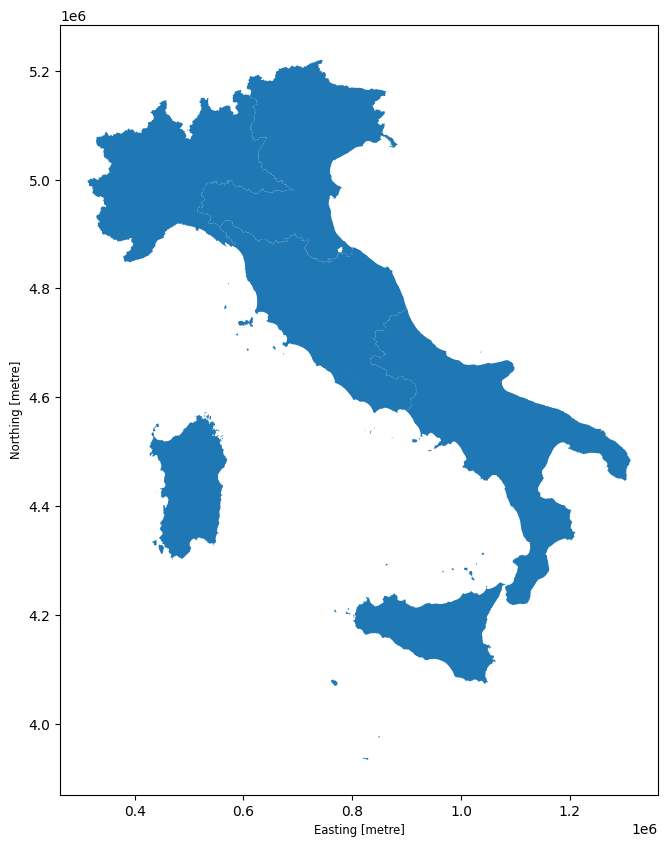

In [134]:
macroregions.plot(figsize=(10,10))

### Block 13 · Learning goal and AI prompt

**Learning objective:** Distinguish plotting from explicitly displaying a figure.

**Check after execution:** Does explicit display change the data or only presentation?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Plot macroregions in a 10 by 10 inch figure and explicitly show it with plt.show. Reuse existing variables and generate only this step. Do not invent results.


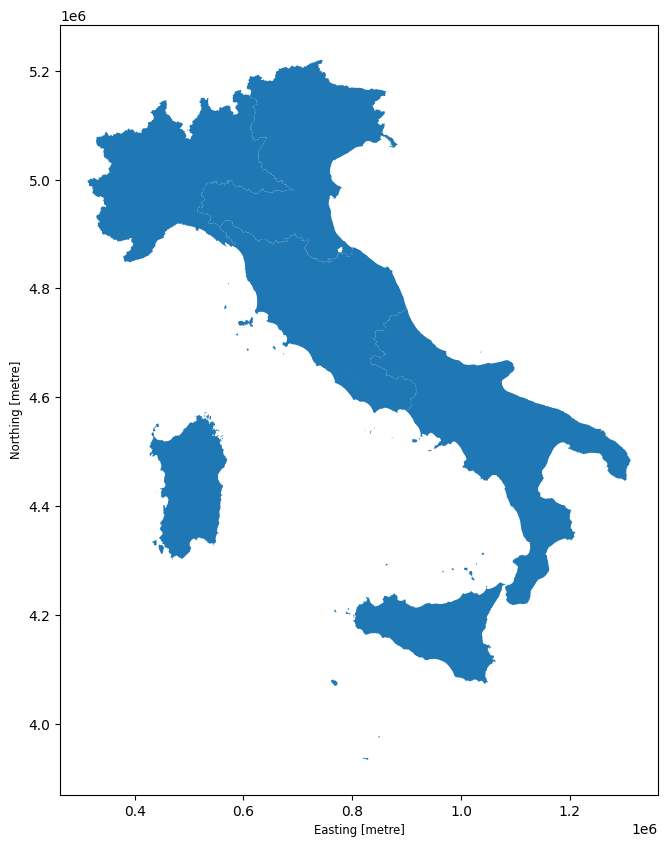

In [135]:
macroregions.plot(figsize=(10,10))
plt.show()

... and new we can use the **classic methods of the pandas DataFrame.**

Eg.

extract a (geo)DataFrame by filter from an attribute

### Block 14 · Learning goal and AI prompt

**Learning objective:** Identify a categorical administrative attribute.

**Check after execution:** How does this label describe the geometry?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the DEN_RIP column of macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [136]:
macroregions['DEN_RIP']

,DEN_RIP
0,Nord-ovest
1,Nord-est
2,Centro
3,Sud
4,Isole


### Block 15 · Learning goal and AI prompt

**Learning objective:** Inspect categories before writing a filter.

**Check after execution:** Which exact value selects the islands?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. List unique DEN_RIP values in macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [137]:
macroregions.DEN_RIP.unique()

array(['Nord-ovest', 'Nord-est', 'Centro', 'Sud', 'Isole'], dtype=object)

### Block 16 · Learning goal and AI prompt

**Learning objective:** Select spatial features using an attribute.

**Check after execution:** How many records satisfy the condition?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Create islands by filtering macroregions where DEN_RIP equals Isole. Preserve the geometry and CRS. Reuse existing variables and generate only this step. Do not invent results.


In [138]:
islands = macroregions[macroregions['DEN_RIP'] == 'Isole']

### Block 17 · Learning goal and AI prompt

**Learning objective:** Verify an attribute selection visually.

**Check after execution:** Does the selected geography agree with the attribute value?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Plot islands and show the figure. Reuse existing variables and generate only this step. Do not invent results.


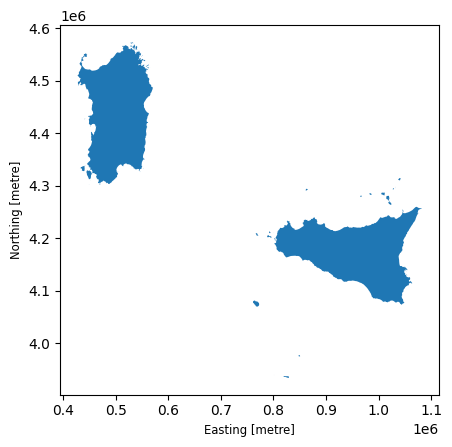

In [139]:
islands.plot()
plt.show()

### Block 18 · Learning goal and AI prompt

**Learning objective:** Distinguish features from multipart geometry components.

**Check after execution:** Can one MultiPolygon represent several disconnected pieces?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the geometry type of every macroregions record. Reuse existing variables and generate only this step. Do not invent results.


In [140]:
macroregions.geom_type

,0
0,MultiPolygon
1,MultiPolygon
2,MultiPolygon
3,MultiPolygon
4,MultiPolygon


A Shapefile layer has one declared geometry family. Polygon records may be multipart. A GeoDataFrame can contain mixed geometry types, subject to the output format.

in our case we have a MultiPolygon
the geometries allowed are:

|geometry|images|
|:--|--:|
|POINT|![](https://upload.wikimedia.org/wikipedia/commons/thumb/c/c2/SFA_Point.svg/51px-SFA_Point.svg.png)|
|LINESTRING|![](https://upload.wikimedia.org/wikipedia/commons/thumb/b/b9/SFA_LineString.svg/51px-SFA_LineString.svg.png)|
|LINEARRING|![](https://raw.githubusercontent.com/napo/geospatial_course_unitn/master/docs/assets/images/linering.png)|
|POLYGON|![](https://upload.wikimedia.org/wikipedia/commons/thumb/3/3f/SFA_Polygon.svg/51px-SFA_Polygon.svg.png)![](https://upload.wikimedia.org/wikipedia/commons/thumb/5/55/SFA_Polygon_with_hole.svg/51px-SFA_Polygon_with_hole.svg.png)
|MULTIPOINT|![](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d6/SFA_MultiPoint.svg/51px-SFA_MultiPoint.svg.png)
| MULITLINESTRING|![](https://upload.wikimedia.org/wikipedia/commons/thumb/8/86/SFA_MultiLineString.svg/51px-SFA_MultiLineString.svg.png)|
| MULTIPOLYGON |![](https://upload.wikimedia.org/wikipedia/commons/thumb/3/3b/SFA_MultiPolygon_with_hole.svg/51px-SFA_MultiPolygon_with_hole.svg.png)|
| GEOMETRYCOLLECTION |![](https://upload.wikimedia.org/wikipedia/commons/thumb/1/1d/SFA_GeometryCollection.svg/51px-SFA_GeometryCollection.svg.png) |

note: table based on the wikipedia page [WKT](https://en.wikipedia.org/wiki/Well-known_text_representation_of_geometry)

#### now we are ready to look how are the geometries

### Block 19 · Learning goal and AI prompt

**Learning objective:** Recognise the geometry of one administrative observation.

**Check after execution:** Can this one observation contain disconnected polygons?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.geometry at index 0, without changing it. Reuse existing variables and generate only this step. Do not invent results.


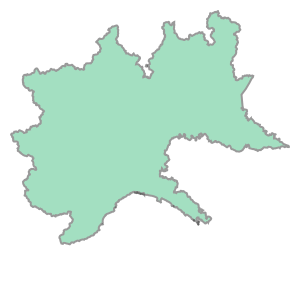

In [141]:
macroregions.geometry[0]

### Block 20 · Learning goal and AI prompt

**Learning objective:** Associate a displayed geometry with its administrative label.

**Check after execution:** Does the label agree with the geometry displayed immediately before?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the DEN_RIP value at index 0 in macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [142]:
macroregions.DEN_RIP[0]


'Nord-ovest'

### Block 21 · Learning goal and AI prompt

**Learning objective:** Recognise the geometry of one administrative observation.

**Check after execution:** Can this one observation contain disconnected polygons?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.geometry at index 1, without changing it. Reuse existing variables and generate only this step. Do not invent results.


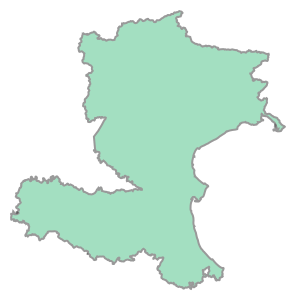

In [143]:
macroregions.geometry[1]

### Block 22 · Learning goal and AI prompt

**Learning objective:** Associate a displayed geometry with its administrative label.

**Check after execution:** Does the label agree with the geometry displayed immediately before?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the DEN_RIP value at index 1 in macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [144]:
macroregions.DEN_RIP[1]


'Nord-est'

### Block 23 · Learning goal and AI prompt

**Learning objective:** Recognise the geometry of one administrative observation.

**Check after execution:** Can this one observation contain disconnected polygons?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.geometry at index 2, without changing it. Reuse existing variables and generate only this step. Do not invent results.


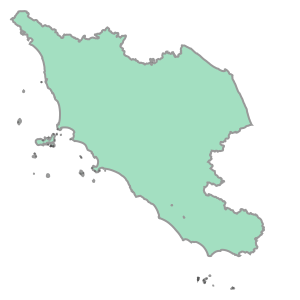

In [145]:
macroregions.geometry[2]

### Block 24 · Learning goal and AI prompt

**Learning objective:** Associate a displayed geometry with its administrative label.

**Check after execution:** Does the label agree with the geometry displayed immediately before?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the DEN_RIP value at index 2 in macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [146]:
macroregions.DEN_RIP[2]


'Centro'

### Block 25 · Learning goal and AI prompt

**Learning objective:** Recognise the geometry of one administrative observation.

**Check after execution:** Can this one observation contain disconnected polygons?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.geometry at index 3, without changing it. Reuse existing variables and generate only this step. Do not invent results.


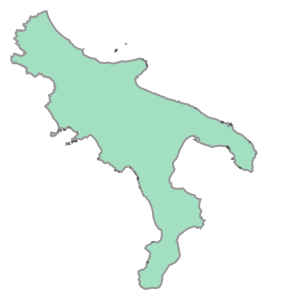

In [147]:
macroregions.geometry[3]

### Block 26 · Learning goal and AI prompt

**Learning objective:** Associate a displayed geometry with its administrative label.

**Check after execution:** Does the label agree with the geometry displayed immediately before?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the DEN_RIP value at index 3 in macroregions. Reuse existing variables and generate only this step. Do not invent results.


In [148]:
macroregions.DEN_RIP[3]


'Sud'

### Block 27 · Learning goal and AI prompt

**Learning objective:** Recognise the geometry of one administrative observation.

**Check after execution:** Can this one observation contain disconnected polygons?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.geometry at index 4, without changing it. Reuse existing variables and generate only this step. Do not invent results.


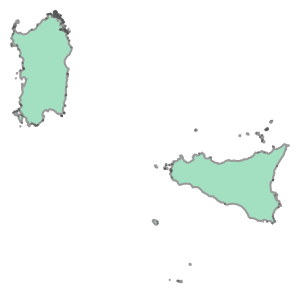

In [149]:
macroregions.geometry[4]

#### Do you want know the centroid position of each geometry?

### Block 28 · Learning goal and AI prompt

**Learning objective:** Interpret a centroid as a geometric summary.

**Check after execution:** Must a centroid lie inside its polygon?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Calculate centroids of macroregions in their existing projected CRS. Reuse existing variables and generate only this step. Do not invent results.


In [150]:
macroregions.geometry.centroid

,0
0,POINT (478136.175 5011442.987)
1,POINT (702039.162 5039725.531)
2,POINT (756686.722 4757568.967)
3,POINT (1061520.33 4529729.424)
4,POINT (736469.127 4300313.952)


the output of the geometries is in [well knowtext format (WKT)](https://en.wikipedia.org/wiki/Well-known_text_representation_of_geometry)

but ... how are expressed the coordinates??
we have to know the Coordinate Reference System (CRS)

# SPATIAL PROJECTIONS

**CRS** = *Coordinate Reference System*

## The Earth isn't FLAT
### The true size
![](https://raw.githubusercontent.com/napo/geospatial_datascience_unitn_2023/main/images/truesize.gif)

https://thetruesize.com/

## How to convert in latitude/longitude?

### Block 29 · Learning goal and AI prompt

**Learning objective:** Read a CRS rather than guessing from coordinate values.

**Check after execution:** What are its datum, projection and units?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions.crs. Reuse existing variables and generate only this step. Do not invent results.


In [151]:
macroregions.crs

<Projected CRS: EPSG:32632>
Name: WGS 84 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 6°E and 12°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Austria. Cameroon. Denmark. Equatorial Guinea. France. Gabon. Germany. Italy. Libya. Liechtenstein. Monaco. Netherlands. Niger. Nigeria. Norway. Sao Tome and Principe. Svalbard. Sweden. Switzerland. Tunisia. Vatican City State.
- bounds: (6.0, 0.0, 12.0, 84.0)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## EPSG?
European Petroleum Survey Group  (1986-2005)<br/>
[IOGP](https://www.iogp.org/about-us/) - International Association of Oil & Gas Producers (2005-now)

An important project is the [EPSG registry](http://www.epsg-registry.org/) - the dataset of geodetic parameters

[http://epsg.io/32632](http://epsg.io/32632)

![](https://github.com/napo/geospatial_course_unitn/raw/master/docs/assets/images/epsg32632.png)

![](https://upload.wikimedia.org/wikipedia/commons/b/b9/Usgs_map_traverse_mercator.PNG)

![](https://upload.wikimedia.org/wikipedia/commons/e/ed/Utm-zones.jpg)

### Block 30 · Learning goal and AI prompt

**Learning objective:** Separate point construction from coordinate transformation.

**Check after execution:** Were centroids calculated before or after reprojection?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Calculate macroregion centroids in the source projected CRS, then transform those points to EPSG:4326. Reuse existing variables and generate only this step. Do not invent results.


In [152]:
macroregions.geometry.centroid.to_crs(epsg=4326)

,0
0,POINT (8.72135 45.25614)
1,POINT (11.58522 45.4818)
2,POINT (12.1454 42.92754)
3,POINT (15.64709 40.72676)
4,POINT (11.72374 38.81988)


### Block 31 · Learning goal and AI prompt

**Learning objective:** Observe how coordinates change under reprojection.

**Check after execution:** Are the resulting coordinates longitude and latitude?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Transform macroregions to EPSG:4326 and display the geometry at index 1. Reuse existing variables and generate only this step. Do not invent results.


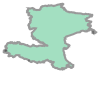

In [153]:
macroregions.to_crs(epsg=4326).geometry[1]

### Block 32 · Learning goal and AI prompt

**Learning objective:** Compare coordinate representations of the same place.

**Check after execution:** What changed compared with the previous cell?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display the original geometry at index 1 in macroregions, without reprojection. Reuse existing variables and generate only this step. Do not invent results.


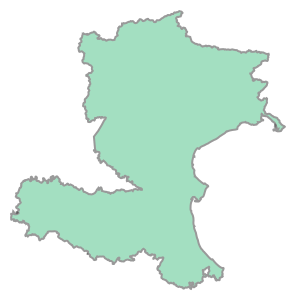

In [154]:
macroregions.geometry[1]

### WGS84 VS ETRS89

|  [WGS84](https://epsg.io/4326)  |  [ETRS89](https://epsg.io/4258) |
|---|---|
|  ![](https://github.com/napo/geospatial_course_unitn/blob/master/images/wgs84_coverage.png?raw=true) | ![](https://github.com/napo/geospatial_course_unitn/blob/master/images/etrs89_coverage.png?raw=true)  

## exploring a .prj file

### Block 33 · Learning goal and AI prompt

**Learning objective:** Locate CRS evidence in source metadata.

**Check after execution:** Does this metadata agree with macroregions.crs?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Read the .prj sidecar beside macroregions_path into prj_text. Reuse existing variables and generate only this step. Do not invent results.


In [155]:
prj_text = macroregions_path.with_suffix(".prj").read_text()

### Block 34 · Learning goal and AI prompt

**Learning objective:** Interpret the CRS declaration directly.

**Check after execution:** Which parts identify the projection and units?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Print prj_text without modifying it. Reuse existing variables and generate only this step. Do not invent results.


In [156]:
print(prj_text)

PROJCS["WGS_1984_UTM_Zone_32N",GEOGCS["GCS_WGS_1984",DATUM["D_WGS_1984",SPHEROID["WGS_1984",6378137.0,298.257223563]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["False_Easting",500000.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",9.0],PARAMETER["Scale_Factor",0.9996],PARAMETER["Latitude_Of_Origin",0.0],UNIT["Meter",1.0]]


... like here

[http://epsg.io/32632.wkt](http://epsg.io/32632.wkt)

here a "pretty" version

[http://epsg.io/32632.wkt](http://epsg.io/32632.wkt)

## save the geodataframe


### Block 35 · Learning goal and AI prompt

**Learning objective:** Export a vector layer with an explicit web CRS.

**Check after execution:** How would you check the exported CRS and record count?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Transform macroregions to EPSG:4326 and write macro_regions.geojson with the GeoJSON driver. Reuse existing variables and generate only this step. Do not invent results.


In [157]:
macroregions.to_crs(epsg=4326).to_file('macro_regions.geojson',driver='GeoJSON')

### Block 36 · Learning goal and AI prompt

**Learning objective:** Extract longitude from correctly transformed centroid points.

**Check after execution:** Is x longitude or latitude?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Calculate source-CRS centroids, transform them to EPSG:4326 as centroids_wgs84, then assign their x values to macroregions["lon"]. Reuse existing variables and generate only this step. Do not invent results.


In [158]:
centroids_wgs84 = macroregions.geometry.centroid.to_crs(4326)
macroregions["lon"] = centroids_wgs84.x

### Block 37 · Learning goal and AI prompt

**Learning objective:** Preserve coordinate axis meaning.

**Check after execution:** Do lon and lat refer to the same centroid calculation?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Assign the y values of centroids_wgs84 to macroregions["lat"]. Reuse existing variables and generate only this step. Do not invent results.


In [159]:
macroregions["lat"] = centroids_wgs84.y

### Block 38 · Learning goal and AI prompt

**Learning objective:** Inspect a derived attribute alongside its source geometry.

**Check after execution:** Do added coordinate attributes change the polygon geometries?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Display macroregions with its new lon and lat fields. Reuse existing variables and generate only this step. Do not invent results.


In [160]:
macroregions

,COD_RIP,DEN_RIP,Shape_Leng,Shape_Area,geometry,lon,lat
0,1,Nord-ovest,2.289536e+06,5.792833e+10,"MULTIPOLYGON (((568231.969 4874857.994, 568233...",8.721350,45.256142
1,2,Nord-est,2.268420e+06,6.239401e+10,"MULTIPOLYGON (((618335.21 4893983.16, 618329.9...",11.585222,45.481799
2,3,Centro,1.981598e+06,5.803706e+10,"MULTIPOLYGON (((876027.96 4525207.198, 876222....",12.145397,42.927536
3,4,Sud,2.510121e+06,7.379473e+10,"MULTIPOLYGON (((1099201.423 4270181.967, 10991...",15.647090,40.726764
4,5,Isole,2.778711e+06,4.993934e+10,"MULTIPOLYGON (((822779.053 3935557.494, 822909...",11.723736,38.819882


and visualize on [https://geojson.io](https://geojson.io)

![](https://raw.githubusercontent.com/napo/geospatial_datascience_unitn_2023/main/images/geojsonio.jpg)

# Another source: pharmacy records
Download the original **national** Ministry of Health CSV, snapshot 22 October 2026. Inspect the fields and historical records before building geometries.

Catalogue: https://www.dati.salute.gov.it/it/dataset/farmacie/

IODL 2.0. Some coordinates: © OpenStreetMap contributors. Do not interpret coordinate repetition as duplicate pharmacies.

### Block 39 · Learning goal and AI prompt

**Learning objective:** Inspect a national source before creating a local subset.

**Check after execution:** Why should identifiers and historical dates be inspected before conversion?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Download the Ministry national pharmacy CSV snapshot 2026-10-22 using requests and HTTP error checking. Cache it in DATA as FRM_FARMA_5_20261022.csv. Read it with semicolon delimiter, UTF-8-sig and all fields as strings into pharmacies_raw. Set PHARMACIES_CATALOGUE, PHARMACIES_URL, REFERENCE_DATE and pharmacy_csv. Use https://www.dati.salute.gov.it/sites/default/files/opendata/FRM_FARMA_5_20261022.csv . Display the first rows. Reuse existing variables and generate only this step. Do not invent results.


In [161]:
import urllib3
import ssl
import requests
from requests.adapters import HTTPAdapter

# Suppress insecure request warnings due to disabling SSL verification
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

# Create an SSL Context that lowers the security level for legacy connections
class LegacySslAdapter(HTTPAdapter):
    def init_poolmanager(self, *args, **kwargs):
        ctx = ssl.create_default_context()
        # Lower security level to allow older handshake ciphers
        ctx.set_ciphers('DEFAULT@SECLEVEL=1')
        ctx.options |= 0x4  # OP_LEGACY_SERVER_CONNECT
        ctx.check_hostname = False
        kwargs["ssl_context"] = ctx
        return super().init_poolmanager(*args, **kwargs)

PHARMACIES_CATALOGUE = "https://www.dati.salute.gov.it/it/dataset/farmacie/"
PHARMACIES_URL = "https://www.dati.salute.gov.it/sites/default/files/opendata/FRM_FARMA_5_20261022.csv"
REFERENCE_DATE = pd.Timestamp("2026-10-22")
pharmacy_csv = DATA / "FRM_FARMA_5_20261022.csv"

if not pharmacy_csv.exists():
    session = requests.Session()
    session.mount("https://", LegacySslAdapter())
    response = session.get(PHARMACIES_URL, timeout=120, verify=False)
    response.raise_for_status()
    pharmacy_csv.write_bytes(response.content)

# Keep identifiers as strings and retain the national source unchanged.
pharmacies_raw = pd.read_csv(pharmacy_csv, sep=";", dtype=str, encoding="utf-8-sig")
pharmacies_raw.head()

,cod_farmacia,cod_farmacia_asl,indirizzo,descrizione_farmacia,p_iva,cap,cod_comune,comune,frazione,cod_provincia,...,provincia,cod_regione,regione,data_inizio_validita,data_fine_validita,descrizione_tipologia,codice_tipologia,latitudine,longitudine,localizzazione
0,0,00000,"Via Buggianese, 108",FARMACIA CASABIANCA S.N.C. DEI DOTT.RI PALINI ...,01917380477,51019,047016,PONTE BUGGIANESE,-,047,...,PISTOIA,090,TOSCANA,01/07/2017,31/07/2017,Ordinaria,1,-,-,2
1,1,00000,"Via San Francesco Da Paola, 10",SAN FRANCESCO DA PAOLA,03603780010,10123,001272,TORINO,-,001,...,TORINO,010,PIEMONTE,01/01/2005,30/06/2023,Ordinaria,1,"45,0652154357378","7,68671719343681",1
2,1,00000,"Via San Francesco Da Paola, 10",SAN FRANCESCO DA PAOLA,09384220019,10123,001272,TORINO,-,001,...,TORINO,010,PIEMONTE,01/07/2023,-,Ordinaria,1,"45,0652154357378","7,68671719343681",1
3,2,00000,"Piazza Vittorio Veneto, 10",GALLO MARIO,10170320013,10123,001272,TORINO,-,001,...,TORINO,010,PIEMONTE,01/11/2009,31/01/2015,Ordinaria,1,"45,003342205568","7,60284957264712",1
4,2,00000,"Piazza Vittorio Veneto, 10",ALGOSTINO E DEMICHELIS,00552480014,10123,001272,TORINO,-,001,...,TORINO,010,PIEMONTE,01/01/2005,31/10/2009,Ordinaria,1,"45,003342205568","7,60284957264712",1


### Block 40 · Learning goal and AI prompt

**Learning objective:** Identify the fields needed for spatial and temporal interpretation.

**Check after execution:** What indicates a missing coordinate or an open-ended validity period?

**AI prompt — copy into Colab:**

> Write the next Python cell for this notebook. Inspect pharmacies_raw.columns and display the first rows of cod_farmacia, comune, data_inizio_validita, data_fine_validita, latitudine and longitudine. Reuse existing variables and generate only this step. Do not invent results.


In [162]:
pharmacies_raw.columns
pharmacies_raw[["cod_farmacia", "comune", "data_inizio_validita", "data_fine_validita", "latitudine", "longitudine"]].head()

All Columns in the dataset:
 ['cod_farmacia', 'cod_farmacia_asl', 'indirizzo', 'descrizione_farmacia', 'p_iva', 'cap', 'cod_comune', 'comune', 'frazione', 'cod_provincia', 'sigla_provincia', 'provincia', 'cod_regione', 'regione', 'data_inizio_validita', 'data_fine_validita', 'descrizione_tipologia', 'codice_tipologia', 'latitudine', 'longitudine', 'localizzazione']


,cod_farmacia,comune,data_inizio_validita,data_fine_validita,latitudine,longitudine
0,0,PONTE BUGGIANESE,01/07/2017,31/07/2017,-,-
1,1,TORINO,01/01/2005,30/06/2023,"45,0652154357378","7,68671719343681"
2,1,TORINO,01/07/2023,-,"45,0652154357378","7,68671719343681"
3,2,TORINO,01/11/2009,31/01/2015,"45,003342205568","7,60284957264712"
4,2,TORINO,01/01/2005,31/10/2009,"45,003342205568","7,60284957264712"


## Exercise
1. Load the 2026 provinces and municipalities with `read_istat`. Select Trento (`COD_PROV == 22`).
2. Calculate and compare polygon areas in an appropriate projected CRS. Derive the largest and smallest municipality from the data.
3. Calculate centroids and representative points in the projected CRS, then transform the points to EPSG:4326 and export GeoJSON.
4. Inspect pharmacy validity dates and coordinate values. Which records describe pharmacies at the reference date?
5. Continue with notebook 03 to construct points, investigate coincident coordinates and perform spatial joins.